In [1]:
# Cell 1: Check GPUs, RAM and Internet (Kaggle: Accelerator "GPU T4 x2", Internet on)
import os, time, platform, subprocess, socket

SESSION_START = time.time()
print(f"Python: {platform.python_version()}")

query = subprocess.run(
    ["nvidia-smi", "--query-gpu=index,name,memory.total", "--format=csv,noheader"],
    capture_output=True, text=True
)
if query.returncode != 0:
    raise RuntimeError("找不到 GPU，請於右側 Session options > Accelerator 選擇 GPU T4 x2。")

GPUS = [line.split(", ") for line in query.stdout.strip().splitlines()]
for index, name, memory in GPUS:
    print(f"GPU {index}: {name} ({memory})")
GPU_COUNT = len(GPUS)

try:
    socket.create_connection(("huggingface.co", 443), timeout=10).close()
    print("Internet: OK")
except OSError:
    raise RuntimeError("無網路連線，請於右側 Session options 開啟 Internet on。")

Python: 3.13.15
GPU 0: Tesla T4 (15360 MiB)
GPU 1: Tesla T4 (15360 MiB)
Internet: OK


In [ ]:
# Cell 2: Download Drive folder & match reference images by item name
IN_FOLDER_URL = ""  # 貼上您的 Google Drive 共用資料夾網址；留空則使用內建測試 prompts.json

import glob, json, os, shutil, subprocess, sys

ROOT = "/kaggle/working/imagegen"
INPUT_DIR = os.path.join(ROOT, "in")
REF_DIR = "/tmp/prompts_in"
PROMPTS_PATH = os.path.join(ROOT, "prompts.json")
os.makedirs(INPUT_DIR, exist_ok=True)
os.makedirs(REF_DIR, exist_ok=True)

sources = []
if IN_FOLDER_URL.strip():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown==5.2.0"], check=True)
    import gdown
    shutil.rmtree(REF_DIR, ignore_errors=True)
    os.makedirs(REF_DIR, exist_ok=True)
    gdown.download_folder(IN_FOLDER_URL.strip(), output=REF_DIR, quiet=False, remaining_ok=True)
    sources.append(REF_DIR)
sources.append("/kaggle/input")

found_prompts = [p for s in sources for p in glob.glob(os.path.join(s, "**", "prompts.json"), recursive=True)]
if found_prompts:
    shutil.copy(found_prompts[0], PROMPTS_PATH)
    print(f"已載入外部設定檔：{found_prompts[0]}")
else:
    builtin_prompts = {
        "defaults": {"seed": 42, "ip_scale": 0.45, "pose": "a-pose", "pose_scale": 0.80, "face_refine": True},
        "items": [
            {
                "name": "character-tifa",
                "prompt": "wearing futuristic silver and black cybernetic tactical armor, combat shorts, knee-high boots",
                "pose": "a-pose",
                "seed": 1001
            },
            {
                "name": "character-mage_male",
                "prompt": "30yo Asian male battle mage, short black hair, wearing dark red and gold linen robes, leather bracers",
                "pose": "a-pose",
                "seed": 777
            }
        ]
    }
    with open(PROMPTS_PATH, "w", encoding="utf-8") as f:
        json.dump(builtin_prompts, f, indent=2, ensure_ascii=False)
    print("未提供外部 prompts.json，已建立內建測試設定檔。")

IMG_EXTS = (".png", ".jpg", ".jpeg", ".webp")
ref_images_map = {}
for s in sources:
    for root_dir, _, files in os.walk(s):
        for file in files:
            if file.lower().endswith(IMG_EXTS):
                stem = os.path.splitext(file)[0]
                ref_images_map[stem] = os.path.join(root_dir, file)

with open(PROMPTS_PATH, "r", encoding="utf-8") as f:
    prompts_data = json.load(f)

todo = [item for item in prompts_data.get("items", []) if not item.get("done")]
default_pose = prompts_data.get("defaults", {}).get("pose", "a-pose")
print(f"\n共 {len(prompts_data.get('items', []))} 筆項目，待處理 {len(todo)} 筆：")
for item in todo:
    name = item["name"]
    short_name = name.split("-", 1)[1] if "-" in name else name
    ref_path = ref_images_map.get(name) or ref_images_map.get(short_name)
    item["_ref_image"] = ref_path or ""
    pose_name = item.get("pose", default_pose)
    if ref_path:
        print(f"  - {name}: [參考圖: {os.path.basename(ref_path)}] | 姿勢={pose_name} | 身材=自動分析(或依body欄位)")
    else:
        print(f"  - {name}: [純文字模式] | 姿勢={pose_name}")

with open(PROMPTS_PATH, "w", encoding="utf-8") as f:
    json.dump(prompts_data, f, indent=2, ensure_ascii=False)

Retrieving folder contents


Processing file 1uZjsKyWcRI8lWr4KsoZz3qFDj7DEEJ6R character-tifa.jpg
Processing file 1F8VBBA5eIdFVl5RfSslVlZYFrDWs1Osm prompts.json


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1uZjsKyWcRI8lWr4KsoZz3qFDj7DEEJ6R
To: /tmp/prompts_in/character-tifa.jpg
100%|██████████| 15.4k/15.4k [00:00<00:00, 20.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1F8VBBA5eIdFVl5RfSslVlZYFrDWs1Osm
To: /tmp/prompts_in/prompts.json
100%|██████████| 805/805 [00:00<00:00, 1.46MB/s]

已載入外部設定檔：/tmp/prompts_in/prompts.json

共 3 筆項目，待處理 3 筆：
  - character-tifa: [參考圖: character-tifa.jpg] | 姿勢=a-pose | 身材=自動分析(或依body欄位)
  - character-knight_female: [純文字模式] | 姿勢=a-pose
  - character-mage_male: [純文字模式] | 姿勢=t-pose



Download completed


In [3]:
# Cell 3: Install dependencies, download models, and write multi-stage worker script
import os, subprocess, sys, time

MARK = "/tmp/.realvis_pipeline_v3"
CONSTRAINTS = "/tmp/constraints.txt"
HF_CACHE = "/tmp/hf_cache"
REMBG_CACHE = "/tmp/rembg_cache"
os.makedirs(HF_CACHE, exist_ok=True)
os.makedirs(REMBG_CACHE, exist_ok=True)
os.environ["HF_HOME"] = HF_CACHE

PINNED = [
    "transformers==4.57.3", "diffusers==0.34.0", "huggingface_hub==0.36.0",
    "accelerate==1.10.1", "peft==0.17.1", "einops==0.8.1", "onnxruntime==1.22.1",
    "pooch==1.8.2", "hf_xet"
]
PINNED_NO_DEPS = ["rembg==2.0.67", "pymatting==1.1.14"]

def sh(cmd):
    print("$", cmd, flush=True)
    res = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if res.returncode != 0:
        print(res.stdout[-2000:], res.stderr[-2000:])
        raise RuntimeError(f"Command failed: {cmd}")

if not os.path.exists(MARK):
    frozen = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
    keep = ("numpy==", "scipy==", "torch==", "torchvision==", "triton==", "numba==", "llvmlite==",
            "pillow==", "opencv-python==", "opencv-python-headless==", "scikit-image==")
    with open(CONSTRAINTS, "w") as f:
        f.write("".join(line + "\n" for line in frozen.splitlines() if line.lower().startswith(keep)))
    sh(f"pip install -q -c {CONSTRAINTS} " + " ".join(f"'{p}'" for p in PINNED))
    sh(f"pip install -q -c {CONSTRAINTS} --no-deps " + " ".join(PINNED_NO_DEPS))
    open(MARK, "w").close()

from huggingface_hub import snapshot_download
t0 = time.time()
print("正在準備 RealVisXL_V4.0、IP-Adapter Face 與 ControlNet OpenPose SDXL...")
snapshot_download("madebyollin/sdxl-vae-fp16-fix")
snapshot_download("SG161222/RealVisXL_V4.0", allow_patterns=[
    "model_index.json", "scheduler/*", "text_encoder/*", "text_encoder_2/*",
    "tokenizer/*", "tokenizer_2/*", "unet/*fp16*", "unet/config.json", "vae/*fp16*", "vae/config.json"
])
snapshot_download("h94/IP-Adapter", allow_patterns=[
    "models/image_encoder/*", "sdxl_models/ip-adapter-plus-face_sdxl_vit-h.safetensors"
])
snapshot_download("thibaud/controlnet-openpose-sdxl-1.0", allow_patterns=["*.json", "*.safetensors"])
print(f"模型準備完成，耗時 {(time.time() - t0) / 60:.1f} 分鐘。")

worker_code = '''import argparse, json, math, os, cv2, numpy as np, torch
from PIL import Image, ImageFilter
from transformers import CLIPVisionModelWithProjection, CLIPImageProcessor
from diffusers import (
    StableDiffusionXLControlNetPipeline,
    StableDiffusionXLInpaintPipeline,
    ControlNetModel, AutoencoderKL, DPMSolverMultistepScheduler
)
from rembg import new_session, remove

# ==============================================================================
# 【姿勢設定與自訂修改指南 (POSE PRESETS)】
# 每個數值皆為相對於畫布寬度 (w) 與高度 (h) 的比例：
#   - arm_dx1, arm_dy1: 手肘距離肩膀的「水平張開距離」與「垂直高度」
#   - arm_dx2, arm_dy2: 手腕距離肩膀的「水平張開距離」與「垂直高度」
#   - leg_dx          : 雙腳腳踝距離中心線的「水平跨步寬度」
# 若未來想新增或微調姿勢，只需修改下方字典的數字，並在 prompts.json 指定 "pose" 名稱即可！
# ==============================================================================
POSE_PRESETS = {
    # 標準 A-Pose（雙手斜下張開約 35 度，最推薦用於 Hunyuan3D 建模，腋下不沾黏）
    "a-pose":        {"arm_dx1": 0.19, "arm_dy1": 0.33, "arm_dx2": 0.26, "arm_dy2": 0.46, "leg_dx": 0.08},
    # 寬版 A-Pose（雙手張開約 55 度，適合穿寬大盔甲或長袍的角色）
    "wide-a-pose":   {"arm_dx1": 0.23, "arm_dy1": 0.29, "arm_dx2": 0.34, "arm_dy2": 0.38, "leg_dx": 0.10},
    # 標準 T-Pose（雙手水平 90 度平舉，傳統骨骼綁定用）
    "t-pose":        {"arm_dx1": 0.24, "arm_dy1": 0.20, "arm_dx2": 0.38, "arm_dy2": 0.20, "leg_dx": 0.08},
    # 自然站姿（雙手微貼身體兩側垂直向下）
    "straight":      {"arm_dx1": 0.14, "arm_dy1": 0.34, "arm_dx2": 0.16, "arm_dy2": 0.48, "leg_dx": 0.06},
    # 雙手插腰展示姿（手肘向外彎曲、手腕收在腰部）
    "hands-on-hips": {"arm_dx1": 0.24, "arm_dy1": 0.32, "arm_dx2": 0.11, "arm_dy2": 0.43, "leg_dx": 0.09},
}

def make_openpose_map(pose_name="a-pose", w=832, h=1216):
    """根據 POSE_PRESETS 繪製對稱全身 OpenPose 骨架圖"""
    p = POSE_PRESETS.get(pose_name.lower(), POSE_PRESETS["a-pose"])
    canvas = np.zeros((h, w, 3), dtype=np.uint8)
    cx = w // 2
    pts = {
        0:  (cx, int(h * 0.115)),                        # 鼻頭
        1:  (cx, int(h * 0.190)),                        # 頸部
        2:  (cx - int(w * 0.11), int(h * 0.20)),         # 右肩
        3:  (cx - int(w * p["arm_dx1"]), int(h * p["arm_dy1"])), # 右手肘
        4:  (cx - int(w * p["arm_dx2"]), int(h * p["arm_dy2"])), # 右手腕
        5:  (cx + int(w * 0.11), int(h * 0.20)),         # 左肩
        6:  (cx + int(w * p["arm_dx1"]), int(h * p["arm_dy1"])), # 左手肘
        7:  (cx + int(w * p["arm_dx2"]), int(h * p["arm_dy2"])), # 左手腕
        8:  (cx - int(w * 0.07), int(h * 0.47)),         # 右髖
        9:  (cx - int(w * p["leg_dx"]), int(h * 0.68)),  # 右膝
        10: (cx - int(w * p["leg_dx"]), int(h * 0.89)),  # 右踝
        11: (cx + int(w * 0.07), int(h * 0.47)),         # 左髖
        12: (cx + int(w * p["leg_dx"]), int(h * 0.68)),  # 左膝
        13: (cx + int(w * p["leg_dx"]), int(h * 0.89)),  # 左踝
        14: (cx - int(w * 0.03), int(h * 0.10)),         # 右眼
        15: (cx + int(w * 0.03), int(h * 0.10)),         # 左眼
        16: (cx - int(w * 0.06), int(h * 0.11)),         # 右耳
        17: (cx + int(w * 0.06), int(h * 0.11)),         # 左耳
    }
    limbs = [
        (1, 2, (255, 0, 0)), (1, 5, (255, 85, 0)), (2, 3, (255, 170, 0)), (3, 4, (255, 255, 0)),
        (5, 6, (170, 255, 0)), (6, 7, (85, 255, 0)), (1, 8, (0, 255, 0)), (8, 9, (0, 255, 85)),
        (9, 10, (0, 255, 170)), (1, 11, (0, 255, 255)), (11, 12, (0, 170, 255)), (12, 13, (0, 85, 255)),
        (1, 0, (0, 0, 255)), (0, 14, (255, 0, 170)), (14, 16, (255, 0, 255)), (0, 15, (170, 0, 255)), (15, 17, (255, 0, 85))
    ]
    for i1, i2, col in limbs:
        p1, p2 = pts[i1], pts[i2]
        mx, my = (p1[0] + p2[0]) // 2, (p1[1] + p2[1]) // 2
        length = math.hypot(p1[0] - p2[0], p1[1] - p2[1])
        angle = math.degrees(math.atan2(p2[1] - p1[1], p2[0] - p1[0]))
        poly = cv2.ellipse2Poly((mx, my), (int(length / 2), 6), int(angle), 0, 360, 1)
        cv2.fillConvexPoly(canvas, poly, col)
    for pt in pts.values():
        cv2.circle(canvas, pt, 6, (255, 255, 255), thickness=-1)
    return Image.fromarray(canvas)

def load_rgb(path):
    img = Image.open(path)
    if img.mode == "RGBA":
        bg = Image.new("RGB", img.size, (128, 128, 128))
        bg.paste(img, mask=img.split()[3])
        return bg
    return img.convert("RGB")

def crop_head(img):
    """自動裁切參考圖或生成圖的頭部區域"""
    w, h = img.size
    cv_img = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)
    gray = cv2.cvtColor(cv_img, cv2.COLOR_BGR2GRAY)
    cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    faces = cascade.detectMultiScale(gray, 1.1, 4)
    if len(faces) > 0:
        x, y, fw, fh = max(faces, key=lambda b: b[2] * b[3])
        cx, cy = x + fw // 2, y + fh // 2
        half = int(max(fw, fh) * 0.95)
        box = (max(0, cx - half), max(0, cy - half), min(w, cx + half), min(h, cy + half))
    else:
        side = int(min(w, h * 0.42))
        left = max(0, (w - side) // 2)
        box = (left, 0, min(w, left + side), min(h, side))
    return img.crop(box).resize((512, 512), Image.Resampling.LANCZOS), box

def auto_analyze_ref_attributes(full_img, pipe):
    """
    【第一層：自動從參考圖分析人種、身材、髮型】
    使用 OpenCLIP Text-Image 相似度零樣本分析全身參考圖，不讀取原圖衣服
    """
    proc = CLIPImageProcessor()
    pixel_values = proc(images=full_img, return_tensors="pt").pixel_values.to("cuda", dtype=torch.float16)
    with torch.no_grad():
        img_embeds = pipe.image_encoder(pixel_values).image_embeds
        img_embeds = img_embeds / img_embeds.norm(dim=-1, keepdim=True)

    def pick_best(candidates):
        tokens = pipe.tokenizer_2(candidates, padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids.to("cuda")
        with torch.no_grad():
            txt_embeds = pipe.text_encoder_2(tokens)[0]
            txt_embeds = txt_embeds / txt_embeds.norm(dim=-1, keepdim=True)
            scores = (img_embeds @ txt_embeds.T).squeeze(0)
        return candidates[int(scores.argmax().item())]

    # 1. 自動判斷性別與人種氣質（動漫人物會自動映射為最契合的東亞/日系或歐美真人五官）
    ethnicity_gender = pick_best([
        "gorgeous young Japanese woman, East Asian facial features",
        "gorgeous young European woman, Caucasian facial features",
        "handsome young East Asian man, sharp masculine face",
        "handsome young European man, masculine face"
    ])
    # 2. 自動判斷身材與胸圍腰臀比例
    body_shape = pick_best([
        "slender curvy hourglass figure, large breasts, narrow waist, toned thighs",
        "slim petite figure, slender body, thin waist",
        "athletic fit figure, toned body, medium bust, long legs",
        "tall muscular athletic build, broad shoulders, strong physique"
    ])
    # 3. 自動判斷髮色與髮型
    hair_style = pick_best([
        "long straight dark brown hair",
        "long straight jet black hair",
        "long blonde hair",
        "long silver white hair",
        "short spiky black hair",
        "short brown hair",
        "ponytail hair"
    ])
    # 4. 自動判斷瞳色
    eye_color = pick_best([
        "reddish brown eyes", "dark brown eyes", "blue eyes", "green eyes", "golden amber eyes"
    ])
    return ethnicity_gender, body_shape, f"{hair_style}, {eye_color}"

def refine_face_region(base_img, head_ref_img, face_prompt, neg_prompt, inpaint_pipe, seed):
    """【第三層：自動臉部高解析度局部重繪 (Face Detailer)】"""
    w, h = base_img.size
    # 針對標準 A-Pose 頭部座標 (cx=w//2, cy=int(h*0.12)) 進行局部放大重繪
    cx, cy = w // 2, int(h * 0.125)
    half = 160
    x1, y1, x2, y2 = max(0, cx - half), max(0, cy - half), min(w, cx + half), min(h, cy + half)
    crop = base_img.crop((x1, y1, x2, y2)).resize((768, 768), Image.Resampling.LANCZOS)

    mask = Image.new("L", (768, 768), 0)
    mask_draw = np.zeros((768, 768), dtype=np.uint8)
    cv2.circle(mask_draw, (384, 384), 290, 255, -1)
    mask = Image.fromarray(mask_draw).filter(ImageFilter.GaussianBlur(24))

    gen = torch.Generator(device="cuda").manual_seed(seed)
    refined = inpaint_pipe(
        prompt=f"RAW closeup portrait, {face_prompt}, photorealistic, detailed eyes, natural skin pores, 8k",
        negative_prompt=neg_prompt,
        image=crop,
        mask_image=mask,
        ip_adapter_image=head_ref_img,
        num_inference_steps=22,
        strength=0.38,
        guidance_scale=6.0,
        generator=gen
    ).images[0]

    refined_small = refined.resize((x2 - x1, y2 - y1), Image.Resampling.LANCZOS)
    mask_small = mask.resize((x2 - x1, y2 - y1), Image.Resampling.LANCZOS)
    out = base_img.copy()
    out.paste(refined_small, (x1, y1), mask_small)
    return out

def pad_to_square_rgba(rgba_img, target_size=1024):
    rgba_img.thumbnail((target_size, target_size), Image.Resampling.LANCZOS)
    canvas = Image.new("RGBA", (target_size, target_size), (0, 0, 0, 0))
    canvas.paste(rgba_img, ((target_size - rgba_img.width) // 2, (target_size - rgba_img.height) // 2), rgba_img)
    return canvas

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--prompts", required=True)
    parser.add_argument("--out_dir", required=True)
    parser.add_argument("--worker", type=int, default=0)
    parser.add_argument("--workers", type=int, default=1)
    args = parser.parse_args()

    with open(args.prompts, "r", encoding="utf-8") as f:
        data = json.load(f)

    defaults = data.get("defaults", {})
    default_seed = int(defaults.get("seed", 42))
    default_ip_scale = float(defaults.get("ip_scale", 0.45))
    default_pose = defaults.get("pose", "a-pose")
    default_pose_scale = float(defaults.get("pose_scale", 0.80))
    default_face_refine = bool(defaults.get("face_refine", True))

    todo = [item for idx, item in enumerate(data.get("items", [])) if not item.get("done") and idx % args.workers == args.worker]
    if not todo:
        print("model ready (無分配任務)", flush=True)
        return

    vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
    image_encoder = CLIPVisionModelWithProjection.from_pretrained("h94/IP-Adapter", subfolder="models/image_encoder", torch_dtype=torch.float16)
    controlnet = ControlNetModel.from_pretrained("thibaud/controlnet-openpose-sdxl-1.0", torch_dtype=torch.float16)

    pipe = StableDiffusionXLControlNetPipeline.from_pretrained(
        "SG161222/RealVisXL_V4.0", vae=vae, controlnet=controlnet, image_encoder=image_encoder,
        torch_dtype=torch.float16, variant="fp16", use_safetensors=True
    ).to("cuda")
    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config, use_karras_sigmas=True, algorithm_type="dpmsolver++")
    pipe.load_ip_adapter("h94/IP-Adapter", subfolder="sdxl_models", weight_name="ip-adapter-plus-face_sdxl_vit-h.safetensors")

    # 共用底層元件建立第三層臉部重繪 Pipeline（不額外佔用顯存）
    inpaint_pipe = StableDiffusionXLInpaintPipeline(
        vae=pipe.vae, text_encoder=pipe.text_encoder, text_encoder_2=pipe.text_encoder_2,
        tokenizer=pipe.tokenizer, tokenizer_2=pipe.tokenizer_2, unet=pipe.unet,
        scheduler=pipe.scheduler, image_encoder=pipe.image_encoder, feature_extractor=pipe.feature_extractor
    ).to("cuda")

    rembg_session = new_session("isnet-general-use")
    dummy_img = Image.new("RGB", (512, 512), (128, 128, 128))
    print("model ready", flush=True)

    neg_prompt = (
        "bald, anime, 2d, illustration, cgi, 3d render, doll, plastic skin, "
        "crossed arms, deformed eyes, bad anatomy, mutated hands, extra limbs, blurry, cropped, weapon"
    )

    for item in todo:
        name = item["name"]
        out_png = os.path.join(args.out_dir, f"{name}-front.png")
        seed = int(item.get("seed", default_seed))
        pose_name = item.get("pose", default_pose)
        ref_path = item.get("_ref_image", "")
        is_char = name.startswith("character-")

        if ref_path and os.path.exists(ref_path):
            full_ref = load_rgb(ref_path)
            head_ref, _ = crop_head(full_ref)
            eth_gen, auto_body, auto_hair = auto_analyze_ref_attributes(full_ref, pipe)
            body_desc = item.get("body") or f"{eth_gen}, {auto_body}, {auto_hair}"
            ip_scale = float(item.get("ip_scale", default_ip_scale))
            pipe.set_ip_adapter_scale(ip_scale)
            print(f"[{name}] 自動分析參考圖特徵 -> {body_desc}", flush=True)
        else:
            head_ref = dummy_img
            body_desc = item.get("body", "realistic person, proportionate body")
            pipe.set_ip_adapter_scale(0.0)
            print(f"[{name}] 純文字模式生成...", flush=True)

        # 【第二層：雙編碼器智慧分流，徹底解決 77 Token 截斷限制】
        # prompt (CLIP-L, <=77 tokens): 專注於「人種五官 + 您指定的服裝」
        prompt_1 = f"RAW photo, {body_desc}, {item['prompt']}, photorealistic, detailed face"
        # prompt_2 (OpenCLIP-G, <=77 tokens): 專注於「全身對稱姿勢 + 3D建模專用平光純灰背景」
        pose_text = f"full body standing in symmetrical {pose_name}, front view, looking straight ahead" if is_char else "isolated object, front view"
        prompt_2 = f"{pose_text}, {body_desc}, natural skin texture, even studio lighting, solid neutral grey background, 8k uhd"

        w, h = (832, 1216) if is_char else (1024, 1024)
        c_img = make_openpose_map(pose_name, w, h) if is_char else Image.new("RGB", (1024, 1024), (0, 0, 0))
        c_scale = float(item.get("pose_scale", default_pose_scale)) if is_char else 0.0

        gen = torch.Generator(device="cuda").manual_seed(seed)
        img = pipe(
            prompt=prompt_1,
            prompt_2=prompt_2,
            negative_prompt=neg_prompt,
            negative_prompt_2=neg_prompt,
            image=c_img,
            controlnet_conditioning_scale=c_scale,
            ip_adapter_image=head_ref,
            width=w,
            height=h,
            num_inference_steps=32,
            guidance_scale=6.5,
            generator=gen
        ).images[0]

        # 【第三層：自動臉部高清重繪】
        if is_char and bool(item.get("face_refine", default_face_refine)):
            print(f"[{name}] 執行第三層：臉部五官高清重繪 (Face Detailer)...", flush=True)
            img = refine_face_region(img, head_ref, body_desc, neg_prompt, inpaint_pipe, seed)

        rgba = remove(img, session=rembg_session)
        pad_to_square_rgba(rgba, target_size=1024).save(out_png)
        print(f"[{name}] 完成並已儲存：{out_png}", flush=True)

if __name__ == "__main__":
    main()
'''

with open("/tmp/run_front_worker.py", "w", encoding="utf-8") as f:
    f.write(worker_code)
print("三階段生圖核心 /tmp/run_front_worker.py 寫入完成。")

$ pip install -q -c /tmp/constraints.txt 'transformers==4.57.3' 'diffusers==0.34.0' 'huggingface_hub==0.36.0' 'accelerate==1.10.1' 'peft==0.17.1' 'einops==0.8.1' 'onnxruntime==1.22.1' 'pooch==1.8.2' 'hf_xet'
$ pip install -q -c /tmp/constraints.txt --no-deps rembg==2.0.67 pymatting==1.1.14
正在準備 RealVisXL_V4.0、IP-Adapter Face 與 ControlNet OpenPose SDXL...


Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

.gitattributes: 0.00B [00:00, ?B/s]

activation-magnitudes.jpg:   0%|          | 0.00/269k [00:00<?, ?B/s]

...

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

OpenPoseXL2.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

control-lora-openposeXL2-rank256.safeten(…):   0%|          | 0.00/774M [00:00<?, ?B/s]

模型準備完成，耗時 1.6 分鐘。
三階段生圖核心 /tmp/run_front_worker.py 寫入完成。


In [4]:
# Cell 4: Run dual-GPU multi-stage generation & pack into ZIP
import json, os, subprocess, sys, threading, time, zipfile

ready = threading.Event()

def stream_output(gpu_idx, proc):
    for line in proc.stdout:
        if "it/s]" in line or "s/it]" in line or "B/s]" in line:
            continue
        if "model ready" in line:
            ready.set()
        print(f"[GPU {gpu_idx}] {line}", end="", flush=True)
    ready.set()

workers = []
for idx in range(GPU_COUNT):
    env = dict(
        os.environ,
        CUDA_VISIBLE_DEVICES=str(idx),
        HF_HOME=HF_CACHE,
        U2NET_HOME=REMBG_CACHE,
        PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True"
    )
    cmd = [
        sys.executable, "-u", "/tmp/run_front_worker.py",
        "--prompts", PROMPTS_PATH,
        "--out_dir", INPUT_DIR,
        "--worker", str(idx),
        "--workers", str(GPU_COUNT)
    ]
    proc = subprocess.Popen(cmd, env=env, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    threading.Thread(target=stream_output, args=(idx, proc), daemon=True).start()
    workers.append(proc)
    if idx + 1 < GPU_COUNT:
        ready.wait(timeout=10 * 60)
        ready.clear()

for proc in workers:
    proc.wait()

with open(PROMPTS_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

finished_count = 0
for item in data.get("items", []):
    item.pop("_ref_image", None)
    out_file = os.path.join(INPUT_DIR, f"{item['name']}-front.png")
    if os.path.exists(out_file):
        item["done"] = True
        finished_count += 1

with open(PROMPTS_PATH, "w", encoding="utf-8") as f:
    json.dump(data, f, indent=2, ensure_ascii=False)

images = sorted(n for n in os.listdir(INPUT_DIR) if n.endswith(".png"))
archive_path = f"/kaggle/working/imagegen-{time.strftime('%Y%m%d-%H%M')}.zip"
with zipfile.ZipFile(archive_path, "w") as zf:
    for img_name in images:
        zf.write(os.path.join(INPUT_DIR, img_name), f"in/{img_name}")
    zf.write(PROMPTS_PATH, "prompts.json")

print(f"\n全部完成！共產出 {finished_count} 張正面圖，已打包至：{archive_path}")

[GPU 0] `torch_dtype` is deprecated! Use `dtype` instead!
[GPU 0] An error occurred while trying to fetch thibaud/controlnet-openpose-sdxl-1.0: thibaud/controlnet-openpose-sdxl-1.0 does not appear to have a file named diffusion_pytorch_model.safetensors.
[GPU 0] Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
[GPU 0] 
[GPU 0] Downloading data from 'https://github.com/danielgatis/rembg/releases/download/v0.0.0/isnet-general-use.onnx' to file '/tmp/rembg_cache/isnet-general-use.onnx'.
[GPU 0] 
[GPU 0] model ready
[GPU 0] Traceback (most recent call last):
[GPU 0]   File "/tmp/run_front_worker.py", line 297, in <module>
[GPU 0]     main()
[GPU 0]     ~~~~^^
[GPU 0]   File "/tmp/run_front_worker.py", line 249, in main
[GPU 0]     eth_gen, auto_body, auto_hair = auto_analyze_ref_attributes(full_ref, pipe)
[GPU 0]                                     ~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^
[GPU 0]   File "/tmp/run_front_worker.py", line 120, in aut

[1] character-knight_female-front.png


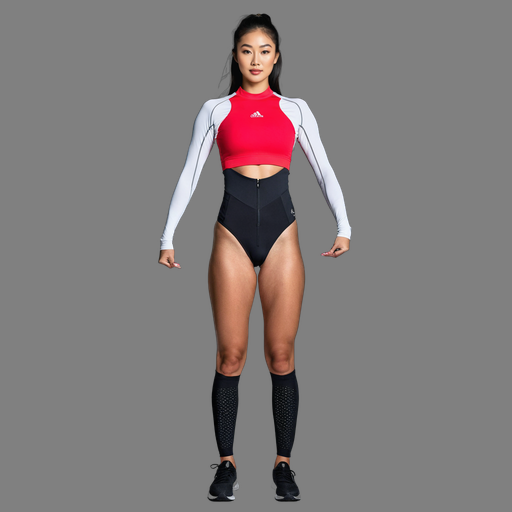

In [5]:
# Cell 5: High-resolution preview
import glob, os
from PIL import Image
from IPython.display import display

fronts = sorted(glob.glob(os.path.join(INPUT_DIR, "*-front.png")))
if not fronts:
    print("尚無生成圖片。")
else:
    tile = 512
    cols = min(len(fronts), 3)
    rows = (len(fronts) + cols - 1) // cols
    sheet = Image.new("RGB", (tile * cols, tile * rows), (128, 128, 128))
    for i, path in enumerate(fronts):
        img = Image.open(path).convert("RGBA")
        img.thumbnail((tile, tile), Image.Resampling.LANCZOS)
        cx = (i % cols) * tile + (tile - img.width) // 2
        cy = (i // cols) * tile + (tile - img.height) // 2
        sheet.paste(img, (cx, cy), img)
        print(f"[{i+1}] {os.path.basename(path)}")
    display(sheet)